## Jezikovni model na osnovi transformerja
Zgradili bomo majhen GPT-2 model in ga naučili govoriti slovensko tako kot Cankar.

## Priprava podatkov
Poglejmo si kako napravimo tokene iz besed. 

- Token (žeton) je osnovna enota besedila, na katero računalnik razdeli besedilo pri obdelavi naravnega jezika. V našem primeru bo token predstavljal kar en znak v besedi. Pomembno: token $\neq$ beseda.

Bolj realistični primeri bi bili:
- računalništvo	$\rightarrow$ računal + ništvo
- programiranje $\rightarrow$ program + iranje
- najlepši $\rightarrow$ naj + lep + ši

<img src="images/tokenization.png" width="800"/>

## Podatki
Na voljo imamo več besedil Ivana Cankarja. Na voljo so v `naloga_2/vaje/data/cankar`. Razdeljena so na drame in na prozo.

In [1]:
import glob
import pickle
import random
import time

import numpy as np

In [2]:
drame_txt = glob.glob("data/cankar/drame/*.txt")
proza_txt = glob.glob("data/cankar/proza/*.txt")

cankar_txt = drame_txt + proza_txt
random.shuffle(cankar_txt)

data = ""
for c_txt in cankar_txt:
    with open(c_txt, "r") as f:
        data += f.read() + "\n\n"

In [3]:
print(data[:1000])

PRVI AKT

V županovi krčmi, ki je opremljena, kakor so opremljene gosposke krčme na deželi. Na levi vhod iz veže, zadaj, za stopnico višje, duri v izbo, na desni okno. V ozadju: na levi velika peč s klopjo, na desni dolga miza.

Prvi prizor

Za mizo sede rodoljubi iz doline šentflorjanske: notar, dacar, štacunar, cerkovnik, županja, ekspeditorica itd. Župan stoji. Vsi so ogorčeni in delajo hude obraze.

Županja. Ampak taka reč!

Ekspeditorica. Joj, taka reč!

Dacar. Hudo čudna reč!

Župan. Ti pa kar molči, gobezdalo dacarsko, ki samo nisi nič boljše! ... Torej, ljudje božji, tako in tako! Vse kaže in mnogotera znamenja pričajo, da se je prikradlo pohujšanje v dolino šentflorjansko. Tam si je postlalo, ob potoku, v tistem brlogu, ki je bil od nekdaj pribežališče vsega smradljivega. Pravi, da mu je Peter ime in da je umetnik. Že to je črno znamenje! Doline šentflorjanske ni blagoslovil Bog zato, da bi redila in pitala umetnike, tatove, razbojnike in druge postopače! Dolina šentflorjanska

In [4]:
print(f"Dolžina besedila v znakih: {len(data):,}")

Dolžina besedila v znakih: 2,483,110


In [5]:
# vsi različni znaki, ki se pojavijo v besedilu
chars = sorted(set(data))
vocab_size = len(chars)  # codebook

print(f"Vsi različni znaki: {''.join(chars)}")
print(f"Velikost besedišča: {vocab_size}")

Vsi različni znaki: 
 !"'(),-.0123456789:;?ABCDEFGHIJKLMNOPRSTUVWZabcdefghijklmnopqrstuvwxyzČčŠšŽž—
Velikost besedišča: 79


- Tokenizer (tokenizator): algoritem, ki razdeli besedilo na žetone in jih pretvori v identifikacijske številke (ID-je).
- Vocabulary (besedišče): zbirka žetonov, ki jih tokenizator prepoznava, pri čemer ima vsak žeton pripadajočo številsko identifikacijsko oznako (ID).

Enostavni primer tokenizatorja je preslikava znaka v celo število

## Naš tokenizer

In [6]:
class SimpleTokenizer:
    """Enostaven tokenizer za nize po znakih."""

    def __init__(self, chars: str) -> None:
        self._ch_to_int = {}
        self._int_to_ch = {}

        for i, ch in enumerate(chars):
            self._ch_to_int[ch] = i
            self._int_to_ch[i] = ch

        self.vocab_size = len(chars)

    def encode(self, s: str) -> list[int]:
        """Niz v seznam celih števil."""
        int_lst = []
        for ch in s:
            int_lst.append(self._ch_to_int[ch])
        return int_lst

    def decode(self, int_lst: list[int]) -> str:
        "Seznam celih števil v niz."
        str_lst = []
        for i in int_lst:
            str_lst.append(self._int_to_ch[i])
        return "".join(str_lst)

    def __call__(self, s: str) -> list[int]:
        return self.encode(s)

In [7]:
# preslikava iz celega števila v znak in obratno
tokenizer = SimpleTokenizer(chars)

In [8]:
np.array(tokenizer("Danes je lep dan za Praktikum Strojnega učenja!"))

array([26, 46, 59, 50, 64,  1, 55, 50,  1, 57, 50, 61,  1, 49, 46, 59,  1,
       71, 46,  1, 38, 63, 46, 56, 65, 54, 56, 66, 58,  1, 40, 65, 63, 60,
       55, 59, 50, 52, 46,  1, 66, 73, 50, 59, 55, 46,  2])

In [9]:
# naredimo učno in validacijsko množico
split_perc = 0.9
n = len(data)
train_data = data[: int(n * split_perc)]
val_data = data[int(n * split_perc) :]

In [10]:
# enkodiramo obe množici v cela števila
train_ids = tokenizer.encode(train_data)
val_ids = tokenizer.encode(val_data)

print(f"Učna množica ima {len(train_ids):,} tokenov.")
print(f"Validacijska množica ima {len(val_ids):,} tokenov.")

Učna množica ima 2,234,799 tokenov.
Validacijska množica ima 248,311 tokenov.


In [11]:
# shranimo naše tokenizirano besedilo v binarne .npy datoteke (uporabno izven notebook-a)
np.save("data/simple_tok_train.npy", np.array(train_ids, dtype=np.uint32))
np.save("data/simple_tok_val.npy", np.array(val_ids, dtype=np.uint32))

In [12]:
# shranimo tokenizer
with open("data/simple_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

## Transformerji

In [13]:
import torch

# izberemo najhitrejšo razpoložljivo napravo: NVIDIA GPU, Apple GPU ali CPU
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Uporabljamo napravo: {device}")

# nastavimo začetek generatorja naključnih števil
seed = 3407
torch.manual_seed(seed)
if device == "cuda":
    torch.cuda.manual_seed(seed)

Uporabljamo napravo: mps


In [14]:
# celotno besedilo je zaporedje celih števil, pretvorimo v PyTorch tenzor
train_data = torch.tensor(train_ids, dtype=torch.long)
val_data = torch.tensor(val_ids, dtype=torch.long)

## Dolžina konteksta

In [15]:
block_size = 8  # context length, največja dolžina napovedi
train_data[: block_size + 1]  # napovedovali bomo kaj pride po nizu celih števil

tensor([38, 39, 43, 31,  1, 23, 33, 41,  0])

In [16]:
x = train_data[:block_size]
y = train_data[1 : block_size + 1]

for i in range(block_size):
    context = x[: i + 1]
    target = y[i]
    # transformer bo videl do block_size, po tem bomo začeli rezati
    print(f"{i}: pri {context.tolist()} je tarča {target}.")

0: pri [38] je tarča 39.
1: pri [38, 39] je tarča 43.
2: pri [38, 39, 43] je tarča 31.
3: pri [38, 39, 43, 31] je tarča 1.
4: pri [38, 39, 43, 31, 1] je tarča 23.
5: pri [38, 39, 43, 31, 1, 23] je tarča 33.
6: pri [38, 39, 43, 31, 1, 23, 33] je tarča 41.
7: pri [38, 39, 43, 31, 1, 23, 33, 41] je tarča 0.


## Velikost paketa

In [17]:
def get_batch(
    train_data: torch.Tensor | None,
    val_data: torch.Tensor | None,
    batch_size: int,
    block_size: int,
    device: str = "cpu",
) -> tuple[torch.Tensor, torch.Tensor]:
    if train_data is not None and val_data is not None:
        raise RuntimeError("Both train and val sets cannot be given.")

    if train_data is not None:
        data = train_data

    if val_data is not None:
        data = val_data

    # izberemo naključne začetne točke za batch
    idx = torch.randint(len(data) - block_size, (batch_size,))  # random offsets

    # vrstice v tenzorju (vrstice so neodvisne)
    x = torch.stack([data[i : i + block_size] for i in idx])  # rabimo za učenje
    y = torch.stack([data[i + 1 : i + block_size + 1] for i in idx])  # rabimo za funkcijo izgube

    return x.to(device), y.to(device)

In [18]:
batch_size = 4  # koliko neodvisnih nizov bomo procesirali na enkrat v forward/backward

x_b, y_b = get_batch(train_data, None, batch_size, block_size, device=device)

print(f"Vhodni podatki ({x_b.shape}):\n{x_b}")
print(f"Tarče ({y_b.shape}):\n{y_b}")

Vhodni podatki (torch.Size([4, 8])):
tensor([[ 1, 54, 59,  1, 61, 63, 60, 64],
        [46,  9,  3,  0,  0,  3, 24, 60],
        [54, 48, 54,  1, 60, 61, 57, 50],
        [54, 75, 57, 60,  1, 59, 46,  1]], device='mps:0')
Tarče (torch.Size([4, 8])):
tensor([[54, 59,  1, 61, 63, 60, 64, 54],
        [ 9,  3,  0,  0,  3, 24, 60, 52],
        [48, 54,  1, 60, 61, 57, 50, 65],
        [75, 57, 60,  1, 59, 46,  1, 58]], device='mps:0')


In [19]:
for b in range(batch_size):
    for i in range(block_size):
        context = x_b[b, : i + 1]
        target = y_b[b, i]
        print(f"Ko je vhodna vrednost {context.tolist()} je tarča {target}.")

Ko je vhodna vrednost [1] je tarča 54.
Ko je vhodna vrednost [1, 54] je tarča 59.
Ko je vhodna vrednost [1, 54, 59] je tarča 1.
Ko je vhodna vrednost [1, 54, 59, 1] je tarča 61.
Ko je vhodna vrednost [1, 54, 59, 1, 61] je tarča 63.
Ko je vhodna vrednost [1, 54, 59, 1, 61, 63] je tarča 60.
Ko je vhodna vrednost [1, 54, 59, 1, 61, 63, 60] je tarča 64.
Ko je vhodna vrednost [1, 54, 59, 1, 61, 63, 60, 64] je tarča 54.
Ko je vhodna vrednost [46] je tarča 9.
Ko je vhodna vrednost [46, 9] je tarča 3.
Ko je vhodna vrednost [46, 9, 3] je tarča 0.
Ko je vhodna vrednost [46, 9, 3, 0] je tarča 0.
Ko je vhodna vrednost [46, 9, 3, 0, 0] je tarča 3.
Ko je vhodna vrednost [46, 9, 3, 0, 0, 3] je tarča 24.
Ko je vhodna vrednost [46, 9, 3, 0, 0, 3, 24] je tarča 60.
Ko je vhodna vrednost [46, 9, 3, 0, 0, 3, 24, 60] je tarča 52.
Ko je vhodna vrednost [54] je tarča 48.
Ko je vhodna vrednost [54, 48] je tarča 54.
Ko je vhodna vrednost [54, 48, 54] je tarča 1.
Ko je vhodna vrednost [54, 48, 54, 1] je tarča 60

## Pogovarjanje med tokeni
Radi bi, da bi token na mestu $n$ videl vse tokene ki so prišli pred njim v $x[:n-1]$ v nekem kontekstnem oknu (a *ne* tistih v prihodnosti). Uporabili bomo matrično množenje s spodnje diagonalno matriko in funkcijo softmax:
$$
\text{softmax}(z)_i=\frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}} \>.
$$

In [20]:
from torch import nn
from torch.nn import functional as F

In [21]:
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)  # podatki, tokeni

tril = torch.tril(torch.ones(T, T))  # spodnje trikotna matrika

# uteži nevronske mreže, to se bomo naučili in bodo odvisne od podatkov
w = torch.zeros((T, T))  # moč interakcije, koliko vsakega tokena iz preteklosti hočemo uporabiti in povprečiti
w = w.masked_fill(tril == 0, float("-inf"))  # tokeni v prihodnosti ne morejo komunicirati
w = F.softmax(w, dim=-1)

In [22]:
w

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])

In [23]:
w @ x  # matrično množenje, weighted aggregation of past elements

tensor([[[ 3.5056e-01,  8.0323e-01],
         [ 2.1855e-01, -7.9559e-02],
         [ 4.2179e-01, -3.4754e-01],
         [ 5.5804e-02, -2.5042e-01],
         [ 1.6101e-01, -2.8000e-01],
         [ 3.7291e-01, -3.3570e-01],
         [ 1.0680e-01, -2.5621e-01],
         [ 5.3798e-03, -1.4911e-01]],

        [[-1.5523e-01, -5.5641e-04],
         [ 3.1595e-01, -7.1448e-01],
         [ 2.9359e-01, -3.3619e-01],
         [ 9.1010e-02, -2.1643e-01],
         [ 3.7122e-01,  3.2910e-02],
         [ 3.8892e-01,  2.0955e-01],
         [ 1.8285e-01,  4.0841e-01],
         [ 4.8306e-02,  4.5399e-01]],

        [[ 4.5776e-02,  5.6051e-01],
         [-1.5038e-02,  3.4160e-01],
         [-7.6500e-02,  1.4965e-01],
         [-5.3653e-01,  3.0166e-01],
         [-3.4015e-01, -5.4247e-01],
         [-3.8653e-01, -3.0202e-01],
         [-3.2768e-01, -2.9710e-01],
         [-3.9146e-01, -3.6574e-01]],

        [[ 2.1948e-01, -1.5861e+00],
         [ 6.3477e-01, -9.2326e-01],
         [ 3.1469e-01, -9.4841e-

## Samopozornost (self-attention)
Vsak token na vsakem položajo bo imel dva vektorja vsakega s svojo vlogo:
- $q$ poizvedba (*query*), kaj gledam?
- $k$ ključ (*key*), kaj vsebujem?

In [24]:
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)

In [25]:
k = key(x)  # (B, T, head_size)
q = query(x)  # (B, T, head_size)

In [26]:
# visoka vrednost pomeni: ta ključ se ujema s to poizvedbo (s tem vprašanjem)
w = torch.matmul(q, k.transpose(-1, -2))  # (B, T, head_size) @ (B, head_size, T) = (B, T, T)

In [27]:
w = w * head_size**-0.5  # zaradi variance

### Vzročna samopozornost

In [28]:
w = w.masked_fill(tril == 0, float("-inf"))
w = F.softmax(w, dim=-1)  # porazdelitev: kdo koga posluša

In [29]:
value = nn.Linear(C, head_size, bias=False)  # definiramo še vrednosti na enak način
v = value(x)  # pove katero informacijo naj vzamemo (w pove koliko, v pove kaj)

In [30]:
out = torch.matmul(w, v)  # utežena vsota vrednosti
out.shape  # (B, T, head_dim)

torch.Size([4, 8, 16])

In [31]:
import matplotlib.pyplot as plt


def plot_weights(w: torch.Tensor, tokens: list[str] | None = None):
    """w: (T, T), vrstice = queries, stolpci = keys."""
    T = w.shape[0]
    tokens = tokens or [str(i) for i in range(T)]

    fig, ax = plt.subplots(figsize=(5, 4.5))
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#eeeeee")
    im = ax.imshow(w.masked_fill(w == 0, float("nan")), cmap=cmap)

    ax.set_xticks(range(T), tokens, rotation=45, ha="right")
    ax.set_yticks(range(T), tokens)
    ax.set_xlabel("ključ (key)")
    ax.set_ylabel("poizvedba (query)")
    ax.set_title("Uteži pozornosti")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="utež")
    fig.tight_layout()
    plt.show()

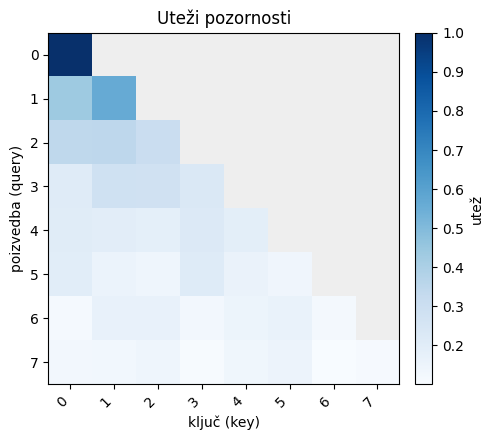

In [32]:
plot_weights(w[0, :, :].detach())

In [33]:
w[0, :, :].sum(dim=-1)  # normalizirano zaradi softmax

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SumBackward1>)

### Samopozornost kot graf

Tokene v nekem kontekstnem oknu si lahko predstavljamo kot vozlišča grafa. Matrika pozornosti $w$ je njegova matrika sosednosti (adjacency matrix). Elementi $w_{ij}$ so uteži usmerjene povezave od tokene $i$ k tokenu $j$ in pove koliko token $i$ "posluša" token $j$.

<img src="images/self_attention_graph.png" width="900"/>

Vsako vozlišče $j$ ima svoje sporočilo, to je vrednost $v_j$. Vsako vozlišče $i$ izbere sporočilo svojih sosedov uteženo z utežmi povezav:
$$
\text{out}_i = \sum_j w_{ij} v_j \>.
$$
Poizvedbe in ključi torej določijo, kdo je s kom povezan (in kako močno), vrednosti pa, kaj potuje po povezavah. To je isto načelo kot pri grafovskih nevronskih mrežah (graph neural networks, GNN), le da graf ni podan vnaprej: model ga z naučenimi preslikavami sproti izračuna iz vhoda.

## Glava modela

In [34]:
# primer razreda za eno glavo pozornosti
class Head(nn.Module):
    tril: torch.Tensor

    def __init__(self, head_size: int, n_embed: int, block_size: int, dropout: int = 0.1) -> None:
        super().__init__()
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)

        self.dropout = nn.Dropout(dropout)  # regularizacija

        self.scale = head_size**-0.5
        self.register_buffer(
            "tril", torch.tril(torch.ones(block_size, block_size))
        )  # ni parameter modela, to je buffer

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Scaled dot-product attention."""
        q = self.query(x)  # (B, T, C)
        k = self.key(x)  # (B, T, C)

        w = torch.matmul(q, k.transpose(-1, -2)) * self.scale  # (B, T, T)
        w = w.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # (B, T, T)
        w = F.softmax(w, dim=-1)  # (B, T, T)

        w = self.dropout(w)

        v = self.value(x)
        out = torch.matmul(w, v)  # (B, T, C)

        return out

## Večglava pozornost (multi-head self-attention)

Namesto da bi izvedli eno samo funkcijo pozornosti s ključi, vrednostmi in poizvedbami dimenzije je koristneje poizvedbe, ključe in vrednosti $h$-krat linearno preslikati z različnimi naučenimi linearnimi preslikavami. Na vsaki od teh preslikanih različic poizvedb, ključev in vrednosti nato vzporedno izvedemo funkcijo pozornosti. Te izhode združimo in ponovno linearno preslikamo, s čimer dobimo končne vrednosti.

Večglava pozornost modelu omogoča, da hkrati upošteva informacije iz različnih podprostorov na različnih položajih. Pri eni sami glavi pozornosti to preprečuje povprečenje.

<img src="images/multihead_attention.png" width="1100"/>
$$
\begin{align}
  q_h &= x\, W_Q^{(h)}, \qquad
  k_h  = x\, W_K^{(h)}, \qquad
  v_h  = x\, W_V^{(h)},
  && h = 1, \dots, n_h, \\[4pt]
  w_h &= \operatorname{softmax}\!\left( \frac{q_h k_h^\top}{\sqrt{h_s}} + M \right),
  \qquad M_{ij} =
     \begin{cases}
       0       & j \le i, \\
       -\infty & j > i,
     \end{cases} \\[4pt]
  o_h &= w_h\, v_h, \\[4pt]
  y   &= \bigl[\, o_1 \;\; o_2 \;\; \cdots \;\; o_{n_h} \,\bigr]\, W_O .
\end{align}
$$

In [35]:
# primer razreda za večglavo pozornost
class MultiHeadAttention(nn.Module):
    def __init__(
        self,
        head_size: int,
        n_embed: int,
        block_size: int,
        num_heads: int,
        dropout: int = 0.1,
    ) -> None:
        super().__init__()
        heads = []
        for _ in range(num_heads):
            heads.append(Head(head_size, n_embed, block_size))

        self.heads = nn.ModuleList(heads)
        self.proj = nn.Linear(num_heads * head_size, n_embed)  # W_O

        self.dropout = nn.Dropout(dropout)  # regularizacija

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Multi-head scaled dot-product attention."""
        heads = []
        for h in self.heads:
            heads.append(h(x))

        heads_cat = torch.cat(heads, dim=-1)  # (B, T, num_heads * head_size)
        return self.dropout(self.proj(heads_cat))  # (B, T, n_embed)

### Optimizirana verzija
Batch način: glave postanejo dodatna os (B, nh, T, hs), zato se množenja za vse primere in vse glave izvedejo v enem klicu.

Hitrejše je, ker je namesto nekaj deset majhnih operacij v zanki le nekaj velikih. Matematično enak kot pri zanki po glavah.

In [36]:
class CausalSelfAttention(nn.Module):
    tril: torch.Tensor

    def __init__(
        self,
        n_embed: int,
        n_head: int,
        head_size: int,
        block_size: int,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        self.n_embed = n_embed
        self.n_head = n_head
        self.head_size = head_size

        self.inner_dim = head_size * n_head
        self.scale = head_size**-0.5

        self.to_qkv = nn.Linear(n_embed, 3 * self.inner_dim, bias=False)
        self.to_out = nn.Linear(self.inner_dim, n_embed, bias=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.output_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "tril",
            torch.ones(block_size, block_size, dtype=torch.bool).view(1, 1, block_size, block_size).tril(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, _ = x.size()

        q, k, v = self.to_qkv(x).split(self.inner_dim, dim=-1)

        q = q.view(B, T, self.n_head, self.head_size).transpose(1, 2)  # (B, nh, T, hs)
        k = k.view(B, T, self.n_head, self.head_size).transpose(1, 2)  # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, self.head_size).transpose(1, 2)  # (B, nh, T, hs)

        attn = (q @ k.transpose(-2, -1)) * self.scale  # (B, nh, T, T)
        attn = attn.masked_fill(~self.tril[:, :, :T, :T], float("-inf"))
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_dropout(attn)

        y = attn @ v  # (B, nh, T, T) @ (B, nh, T, hs) = (B, nh, T, hs)
        y = y.transpose(1, 2).reshape(B, T, self.inner_dim)  # (B, T, nh*hs)

        y = self.output_dropout(self.to_out(y))
        return y

## GPT decoder

Imamo večglavo pozornost. Za celoten model nam manjka še nekaj sestavin:
- vložitvena tabela (embedding table)
- usmerjena nevronska mreža (feed-forward network)
- normalizacija plasti (layer normalization)
- rezidualna povezava (residual connection)
- glava za napovedovanje tokenov (prediction head, language modeling head)

<img src="images/gpt_decoder.png" width="1100"/>

Vsak transformerski blok vsebuje večglavo samopozornost in usmerjeno nevronsko mrežo (feed-forward network). Okoli obeh je rezidualna povezava (residual connection), pred vsakim pa normalizacija plasti (layer normalization). Za regularizacijo uporabimo izpuščanje (dropout). Na koncu modela je glava za napovedovanje tokenov.

### Vložitvena tabela

In [37]:
# ekvivalentno že napisanemu razredu nn.Embedding v PyTorchu-u
class Embedding(nn.Module):
    """Tabela vložitev: vsak token (indeks) dobi svojo vrstico v matriki."""

    def __init__(self, num_embeddings: int, embedding_dim: int) -> None:
        super().__init__()
        # ena vrstica za vsak token
        self.weight = nn.Parameter(torch.randn(num_embeddings, embedding_dim))  # začnemo z N(0, 1)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        # idx: (B, T) celih števil -> (B, T, embedding_dim)
        return self.weight[idx]

In [38]:
# primer kako deluje indeksiranje vrstic
weight = torch.tensor(
    [
        [0.0, 0.0],  # vrstica 0
        [10.0, 11.0],  # vrstica 1
        [20.0, 21.0],  # vrstica 2
        [30.0, 31.0],
    ]
)  # vrstica 3

idx = torch.tensor([[1, 3, 3], [0, 2, 1]])

weight[idx], weight[idx].shape

(tensor([[[10., 11.],
          [30., 31.],
          [30., 31.]],
 
         [[ 0.,  0.],
          [20., 21.],
          [10., 11.]]]),
 torch.Size([2, 3, 2]))

### Usmerjena nevronska mreža

V modernih transformerjih se uporabljajo različne variante:

$$
\begin{align}
  \mathrm{FFN}_{\mathrm{ReLU}}(x, W_1, W_2) &= \max(0,\, x W_1)\, W_2 \\[6pt]
  \mathrm{GLU}(x, W, V) &= \sigma(x W) \otimes x V \\[6pt]
  \mathrm{FFN}_{\mathrm{ReGLU}}(x, W, V, W_2)  &= \bigl(\max(0,\, x W) \otimes x V\bigr)\, W_2 \\
  \mathrm{FFN}_{\mathrm{GEGLU}}(x, W, V, W_2)  &= \bigl(\mathrm{GELU}(x W) \otimes x V\bigr)\, W_2 \\
  \mathrm{FFN}_{\mathrm{SwiGLU}}(x, W, V, W_2) &= \bigl(\mathrm{Swish}_1(x W) \otimes x V\bigr)\, W_2 \\[6pt]
  \mathrm{GELU}(z) &= z\, \Phi(z), \qquad
  \mathrm{Swish}_\beta(z) = z\, \sigma(\beta z), \qquad
  \sigma(z) = \frac{1}{1 + e^{-z}} \\[6pt]
  x \in \mathbb{R}^{C}, \quad
  W, V &\in \mathbb{R}^{C \times d_{\mathrm{ff}}}, \quad
  W_2 \in \mathbb{R}^{d_{\mathrm{ff}} \times C}, \qquad
  d_{\mathrm{ff}}^{\mathrm{GLU}} = \tfrac{2}{3}\, d_{\mathrm{ff}}^{\mathrm{ReLU}}
\end{align}
$$

In [39]:
class FeedForward(nn.Module):
    def __init__(self, n_embed: int, mult: int = 4, dropout: int = 0.1) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embed, mult * n_embed),
            nn.ReLU(),
            nn.Linear(mult * n_embed, n_embed),
            nn.Dropout(dropout),  # izpuščanje nevronov
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)  # na nivoju tokenov

Primer SwiGLU usmerjena nevronske mreže:
<img src="images/swiglu.png" width="900"/>

### Normalizacija plasti

Normalizacija plasti (layer normalization) poskrbi, da imajo vektorji, ki potujejo skozi mrežo, primerljivo velikost. Vsak token obravnava posebej: njegov vektor dolžine $C$ premakne tako, da ima povprečje 0 in varianco 1. Nato ga z naučenimi parametri spet raztegne in premakne, kolikor modelu ustreza:

$$
\begin{align}
  \mu &= \frac{1}{C} \sum_{i=1}^{C} x_i, \qquad
  \sigma^2 = \frac{1}{C} \sum_{i=1}^{C} \left( x_i - \mu \right)^2, \\[6pt]
  \hat{x}_i &= \frac{x_i - \mu}{\sqrt{\sigma^2 + \varepsilon}}, \\[6pt]
  y_i &= \gamma_i\, \hat{x}_i + \beta_i, \qquad i = 1, \dots, C\>.
\end{align}
$$

V globokih mrežah lahko vrednosti po plasteh močno oscilirajo, kar upočasni ali celo pokvari učenje. Normalizacija vsako plast postavi na skupno skalo, zato je učenje stabilnejše.

In [40]:
# ekvivalentno že napisanemu razredu nn.LayerNorm v PyTorchu-u
class LayerNorm(nn.Module):
    """Normalizacija plasti (layer norm)."""

    def __init__(self, dim: int, bias: bool = True, eps: float = 1e-5) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))  # gamma (skala)
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None  # beta (odmik)
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # povprečje in varianca po kanalih, za vsak token posebej
        mean = x.mean(dim=-1, keepdim=True)  # (B, T, 1)
        var = x.var(dim=-1, keepdim=True, unbiased=False)  # (B, T, 1)

        x_hat = (x - mean) / torch.sqrt(var + self.eps)  # (B, T, C), povprečje 0, varianca 1

        out = x_hat * self.weight  # naučena skala
        if self.bias is not None:
            out = out + self.bias  # naučen odmik

        return out

### Blok transformerja
Uporabimo rezidualno povezavo (skip connection). Deluje kot optimizacijski trik za hitrejše učenje modela.

<img src="images/skip.png" width="500"/>

In [41]:
class Block(nn.Module):
    def __init__(
        self,
        n_embed: int,
        n_head: int,
        block_size: int,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        if n_embed % n_head != 0:
            raise ValueError("Number of heads must divide the embedding size.")

        head_size = n_embed // n_head

        self.mha = CausalSelfAttention(n_embed, n_head, head_size, block_size, dropout=dropout)
        self.ff = FeedForward(n_embed, dropout=dropout)

        self.ln1 = LayerNorm(n_embed)
        self.ln2 = LayerNorm(n_embed)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # rezidualne povezave skupaj z normalizacijo
        x = x + self.mha(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x

## GPT
Pa dajmo sestaviti GPT model!

Učili ga bomo s funkcijo izgube NLL (negative log-likelihood):

$$
\begin{align}
  p_\theta(v \mid x_{\le t}) &= \frac{e^{\,\ell_{t,v}}}{\sum_{u=1}^{V} e^{\,\ell_{t,u}}}, \\[6pt]
  \mathcal{L}(\theta) &= -\frac{1}{B\,T} \sum_{b=1}^{B} \sum_{t=1}^{T}
    \log p_\theta\bigl(x^{(b)}_{t+1} \mid x^{(b)}_{\le t}\bigr),
\end{align}
$$

kjer je $\ell_{t,v}$ logit (izhod napovedne glave) za token $v$ na položaju $t$, $V$ velikost besedišča, $B$ velikost paketa in $T$ dolžina konteksta. $x^{(b)}_{t+1}$ je pravilen naslednji token v $b$-tem primeru batcha, $\theta$ pa označuje vse parametre modela.

Če model pravilnemu tokenu pripiše verjetnost blizu 1, je $-\log p \approx 0$. Če mu pripiše majhno verjetnost, je izguba velika.

In [42]:
from dataclasses import dataclass
from typing import Any


@dataclass
class GPTConfig:
    block_size: int = 256  # dolžina konteksta (največje število tokenov naenkrat)
    vocab_size: int = tokenizer.vocab_size  # velikost besedišča (število različnih tokenov)
    n_embd: int = 32  # dimenzija vložitve (C)
    n_layer: int = 4  # število transformerskih blokov
    n_head: int = 4  # število glav pozornosti v vsakem bloku
    dropout: float = 0.05  # verjetnost izpuščanja (dropout)

    @property
    def block_config(self) -> dict[str, Any]:
        return {
            "n_embed": self.n_embd,
            "n_head": self.n_head,
            "block_size": self.block_size,
            "dropout": self.dropout,
        }

In [43]:
class GPT(nn.Module):
    def __init__(self, config: GPTConfig) -> None:
        super().__init__()
        self.config = config

        # plasti transformerja
        layers = []
        for _ in range(config.n_layer):
            layers.append(Block(**config.block_config))

        # naš transformer
        self.transformer = nn.ModuleDict(
            {
                # vložitev za tokene (identiteta tokena)
                "token_embedding_table": Embedding(config.vocab_size, config.n_embd),
                # vložitev za pozicije tokenov
                "position_embedding_table": Embedding(config.block_size, config.n_embd),
                "dropout": nn.Dropout(config.dropout),
                "layers": nn.ModuleList(layers),
                "final_ln": LayerNorm(config.n_embd),
            }
        )

        # glava za napovedovanje
        self.prediction_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # uteži za kodiranje in dekodiranje tokenov so enake (weight tying)
        self.transformer.token_embedding_table.weight = self.prediction_head.weight

        # inicializacija uteži
        self.apply(self._init_weights)

        # preštejemo parametre modela brez pozicijskih vložitev
        print(f"Število parametrov modela: {self._get_num_params():,}.")

    def _init_weights(self, module: nn.Module) -> None:
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        # ostali moduli (LayerNorm, Dropout, ...) ostanejo s privzeto inicializacijo

    def _get_num_params(self) -> int:
        n_params = sum(p.numel() for p in self.parameters())
        n_params -= self.transformer.position_embedding_table.weight.numel()
        return n_params

    def forward(
        self, idx: torch.Tensor, targets: torch.Tensor | None = None
    ) -> tuple[torch.Tensor, torch.Tensor | None]:
        # vsak int bo dobil iz embedding tabele vrstico, ki ustreza njegovemu indeksu
        token_embedding = self.transformer.token_embedding_table(idx)  # (B, T, C), C = n_embed

        pos = torch.arange(idx.shape[1], dtype=torch.long, device=idx.device)  # (T,)
        position_embedding = self.transformer.position_embedding_table(pos)  # (T, C)

        x = token_embedding + position_embedding  # (B, T, C)
        x = self.transformer.dropout(x)

        for layer in self.transformer.layers:
            x = layer(x)

        x = self.transformer.final_ln(x)

        if targets is None:
            # pri generiranju potrebujemo samo napoved za zadnji položaj
            logits = self.prediction_head(x[:, -1, :].unsqueeze(1))  # (B, 1, vocab_size)
            return logits, None

        logits = self.prediction_head(x)  # (B, T, vocab_size)

        # izračunajmo funkcijo izgube
        B, T, vocab_size = logits.shape
        logits_flat = logits.view(B * T, vocab_size)
        targets_flat = targets.view(B * T)
        loss = F.cross_entropy(logits_flat, targets_flat)

        return logits, loss

    def configure_optimizer(
        self, learning_rate: float, weight_decay: float = 0.0, fused: bool = False
    ) -> torch.optim.Optimizer:
        # samo parametri, ki se učijo
        params = [p for p in self.parameters() if p.requires_grad]

        # matrike (dim >= 2): uteži linearnih plasti in tabele vložitev
        decay_params = [p for p in params if p.dim() >= 2]
        # vektorji (dim < 2): odmiki (bias) ter skala in odmik normalizacije plasti
        nodecay_params = [p for p in params if p.dim() < 2]

        optim_groups = [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": nodecay_params, "weight_decay": 0.0},
        ]

        return torch.optim.AdamW(optim_groups, lr=learning_rate, fused=fused)

    @torch.no_grad()
    def generate(
        self, idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_k: int | None = None
    ) -> torch.Tensor:
        for _ in range(max_new_tokens):
            # model vidi največ block_size tokenov, zato obdržimo samo zadnji block_size
            idx_cond = idx[:, -self.config.block_size :]  # (B, min(T, block_size))

            # logiti od modela
            logits, _ = self(idx_cond)

            # zanima nas samo zadnja napoved (lahko skaliramo)
            logits = logits[:, -1, :] / temperature  # (B, vocab_size)

            # obdržimo samo top_k najverjetnejših tokenov, ostalim nastavimo verjetnost 0
            if top_k is not None:
                kth = torch.topk(logits, top_k).values[:, -1].unsqueeze(-1)  # (B, 1): k-ti največji logit
                logits = logits.masked_fill(logits < kth, float("-inf"))  # (B, vocab_size)

            # softmax pretvori logite v verjetnostno porazdelitev
            probs = F.softmax(logits, dim=-1)  # (B, vocab_size)

            # iz porazdelitve naključno izberemo naslednji token
            idx_next = torch.multinomial(probs, num_samples=1)  # (B, 1)

            # novi token dodamo na konec zaporedja in nadaljujemo
            idx = torch.cat((idx, idx_next), dim=1)  # (B, T + 1)

        return idx

## Učenje (optimizacija)

In [44]:
use_checkpoint = True
checkpoint_path = "data/cankar_gpt.pt"

if use_checkpoint:
    checkpoint = torch.load(checkpoint_path, map_location=device)

In [45]:
# odločimo se za parametra učenja
batch_size = 92  # velikost batcha (število zaporedij v enem koraku učenja)
block_size = 128  # velikost konteksta

max_iters = 5000  # skupno število korakov učenja
eval_interval = 200  # na koliko korakov ocenimo učno in validacijsko izgubo
eval_iters = 50  # število batch-ov, po katerih povprečimo izgubo pri oceni izgube

learning_rate = 1.0e-3  # hitrost učenja (velikost koraka optimizatorja)
weight_decay = 1.0e-3  # upadanje uteži (regularizacija)

# pohitritev modela in učenja
compile_model = True
fused_adamw = True

In [46]:
if use_checkpoint:
    # naložimo že naučen model
    config = GPTConfig(**checkpoint["config"])
    history = checkpoint["history"]

    cankar_gpt = GPT(config).to(device)

    state_dict = {k.removeprefix("_orig_mod."): v for k, v in checkpoint["model"].items()}
    cankar_gpt.load_state_dict(state_dict)
    cankar_gpt.eval()
else:
    # naredimo model
    config = GPTConfig(block_size=block_size, n_embd=128, n_layer=6, n_head=4, dropout=0.1)
    cankar_gpt = GPT(config).to(device)

cankar_gpt

Število parametrov modela: 1,196,928.


GPT(
  (transformer): ModuleDict(
    (token_embedding_table): Embedding()
    (position_embedding_table): Embedding()
    (dropout): Dropout(p=0.1, inplace=False)
    (layers): ModuleList(
      (0-5): 6 x Block(
        (mha): CausalSelfAttention(
          (to_qkv): Linear(in_features=128, out_features=384, bias=False)
          (to_out): Linear(in_features=128, out_features=128, bias=False)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (output_dropout): Dropout(p=0.1, inplace=False)
        )
        (ff): FeedForward(
          (net): Sequential(
            (0): Linear(in_features=128, out_features=512, bias=True)
            (1): ReLU()
            (2): Linear(in_features=512, out_features=128, bias=True)
            (3): Dropout(p=0.1, inplace=False)
          )
        )
        (ln1): LayerNorm()
        (ln2): LayerNorm()
      )
    )
    (final_ln): LayerNorm()
  )
  (prediction_head): Linear(in_features=128, out_features=79, bias=False)
)

In [47]:
if compile_model:
    cankar_gpt = torch.compile(cankar_gpt, fullgraph=True, mode="reduce-overhead")

In [48]:
@torch.no_grad()
def estimate_losses(
    model: nn.Module,
    train_data: torch.Tensor,
    val_data: torch.Tensor,
    eval_iters: int,
    batch_size: int,
    block_size: int,
    device: str = "cpu",
) -> torch.Tensor:
    model.eval()
    out = {}
    for split in ["train", "val"]:
        if split == "train":
            train, val = train_data, None
        else:
            train, val = None, val_data

        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):
            x, y = get_batch(train, val, batch_size, block_size, device=device)

            _, loss = model(x, y)
            losses[k] = loss.item()

        out[split] = losses.mean()

    model.train()

    return out

In [49]:
def train() -> dict[int, dict[str, float]]:
    optimizer = cankar_gpt.configure_optimizer(learning_rate, weight_decay, fused=fused_adamw)

    history: dict[int, dict[str, float]] = {}
    train_time = 0.0

    # učna zanka
    for i in range(max_iters):
        # občasno ocenimo učno in validacijsko izgubo
        if i % eval_interval == 0 or i == max_iters:
            losses = estimate_losses(
                cankar_gpt, train_data, val_data, eval_iters, batch_size, block_size, device=device
            )
            history[i] = {"train": losses["train"].item(), "val": losses["val"].item()}

            log = f"Korak {i}: učna izguba {losses['train']:.4f}, validacijska izguba {losses['val']:.4f}."
            if i != 0:
                log += f" Povprečna hitrost: {i / train_time:.2f} it/s."
            log += f" Skupni čas {train_time:.2f} s."
            print(log)

        step_start = time.time()

        x_b, y_b = get_batch(train_data, None, batch_size, block_size, device=device)

        _, loss = cankar_gpt(x_b, y_b)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        train_time += time.time() - step_start

    print(f"Učenje je trajalo {train_time:.2f} s. Povprečna hitrost: {max_iters / train_time:.2f} it/s.")

    return history

In [50]:
if not use_checkpoint:
    history = train()

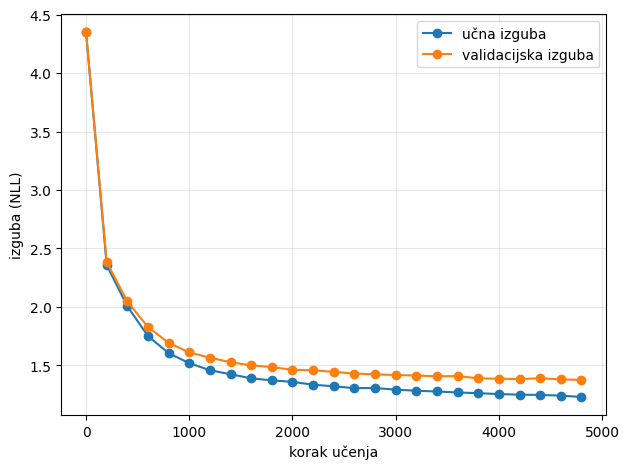

In [51]:
steps = list(history.keys())
train_loss = [h["train"] for h in history.values()]
val_loss = [h["val"] for h in history.values()]

fig, ax = plt.subplots()
ax.plot(steps, train_loss, marker="o", label="učna izguba")
ax.plot(steps, val_loss, marker="o", label="validacijska izguba")

ax.set_xlabel("korak učenja")
ax.set_ylabel("izguba (NLL)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

## Generacija besedila

In [52]:
start = "Validacijska izguba je rasla, in srce mu je "  # začetno besedilo (kontekst), iz katerega model nadaljuje
num_samples = 10  # število generiranih besedil
max_new_tokens = 500  # število novih tokenov v vsakem besedilu
temperature = 1.0  # temperatura: < 1 bolj predvidljivo, > 1 bolj naključno
top_k = None  # izbira samo med top_k najverjetnejšimi tokeni (None = vsi)

In [53]:
cankar_gpt.eval()

start_id = tokenizer.encode(start)
x = torch.tensor(start_id, dtype=torch.long, device=device).unsqueeze(0)

with torch.no_grad():
    for k in range(num_samples):
        print(f"\nVzorec {k}:\n")
        y = cankar_gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
        print(tokenizer.decode(y[0].tolist()))


Vzorec 0:

Validacijska izguba je rasla, in srce mu je zatonilo brus po stolu!

Gornik. Zanesel si ti mi ne bo.

Grudnovka. Dar bo povej, kako ste še res tukaj? Dobro, gospod Ščuka, morda je tako prestrašil in trudno Kačur; ko bodo vvzeli zardelo korakov okrnili, prenašal poesmi misli, da nikjer nikoli srce vzemi ne zagrebe, temveč so bolezen in časih poklice.

"Zakaj sem ti brez besedve skupaj?," je zakriknil Šimnu in je priginil mehke besedo, ali zdramil, pogledal je nanj ustnice, oči so mu še vtisnile oči in ona mu je odpirala na roko in je zavzd

Vzorec 1:

Validacijska izguba je rasla, in srce mu je seglo začudilo.

— Pozno, če vem, da se razjokaš s poslanim očem svojo pozlačenih pesmiško na ljubezni sanjači. Ne Brigačni cesto, po jezikovih kamenetških, temveč njegov pofesarji; le daleč in doktekn, čemu bi jo nubogano. Ti saj bi pojdem razšoren, Mate, kakor ju blagoslovito dni. Grad je zapazil natanko, da se vrni po tvojih lepah in gosti kupi stokati za njima dolina, polne sence,

In [54]:
from dataclasses import asdict

# shranimo model
if not use_checkpoint:
    checkpoint = {
        "model": cankar_gpt.state_dict(),  # uteži modela
        "config": asdict(config),  # nastavitve modela
        "optimizer": optimizer.state_dict(),  # samo, če želiš kasneje nadaljevati učenje
        "iter": max_iters,  # korak, pri katerem smo končali
        "history": history,  # potek izgube
    }
    torch.save(checkpoint, "data/cankar_gpt.pt")

## Literature
- https://arxiv.org/abs/1706.03762
- https://arxiv.org/abs/2604.00965
- https://github.com/lucidrains/vit-pytorch
- https://arxiv.org/abs/2002.05202
- https://arxiv.org/abs/1512.03385